# 00 · Revisión de datos: ¿aguantan el proyecto?

Antes de entrenar nada, respondemos las preguntas que definen el diseño del recomendador:

1. **¿Cuánta historia tiene cada persona?** Si casi todos tienen una sola reseña, no hay mucho para aprender del historial y el *cold start* manda.
2. **¿Qué tan concentradas están las reseñas en pocos productos?** Si es así, "recomendar lo popular" va a ser un baseline difícil de vencer.
3. **¿Qué tan completo está el perfil de piel?** Es lo único que tenemos para recomendar en cold start.
4. **¿Cuántos datos hay por tono de piel?** Define si el análisis de fairness es posible y con qué precisión.
5. **¿Qué significa "le gustó"?** Los ratings están muy cargados hacia el 5.
6. **¿Alcanzan los datos para los splits que planeamos?** Leave-last-out y cold start.

Al final hay una sección de **decisiones** que alimenta el paso 1.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_products, load_reviews, SKIN_TONE_ORDER

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
ROSA, GRIS = "#c2577a", "#9a9a9a"

In [2]:
products = load_products()
reviews = load_reviews()   # usa el parquet de data/interim (lo genera la primera vez)
print(f"Productos: {len(products):,} | Reseñas: {len(reviews):,}")
print(f"Personas: {reviews.author_id.nunique():,} | Productos reseñados: {reviews.product_id.nunique():,}")
print("Rango de fechas:", reviews.submission_time.min().date(), "→", reviews.submission_time.max().date())

Productos: 8,494 | Reseñas: 1,093,895


Personas: 503,216 | Productos reseñados: 2,351
Rango de fechas: 2008-08-28 → 2023-03-21


## 1 · El catálogo: ¿qué productos tienen reseñas?

Las reseñas del dataset son solo de skincare. Veamos qué parte del catálogo cubren y si los productos reseñados tienen las features que queremos usar en la torre del producto (ingredientes, precio, categoría, marca).

In [3]:
reviewed_ids = set(reviews.product_id.unique())
products["tiene_reseñas"] = products.product_id.isin(reviewed_ids)
display(pd.crosstab(products.primary_category, products.tiene_reseñas, margins=True))

items = products[products.tiene_reseñas].copy()
print(f"\nProductos reseñados que no están en product_info: {len(reviewed_ids - set(products.product_id))}")
print("\nFaltantes en features de producto (entre los reseñados):")
display(items[["ingredients", "price_usd", "secondary_category", "tertiary_category", "brand_name", "highlights"]].isna().mean().rename("% faltante").to_frame())

tiene_reseñas,False,True,All
primary_category,,,
Bath & Body,405,0,405
Fragrance,1432,0,1432
Gifts,4,0,4
Hair,1464,0,1464
Makeup,2369,0,2369
Men,60,0,60
Mini Size,288,0,288
Skincare,69,2351,2420
Tools & Brushes,52,0,52



Productos reseñados que no están en product_info: 0

Faltantes en features de producto (entre los reseñados):


,% faltante
ingredients,0.054
price_usd,0.000
secondary_category,0.000
tertiary_category,0.150
brand_name,0.000
highlights,0.176


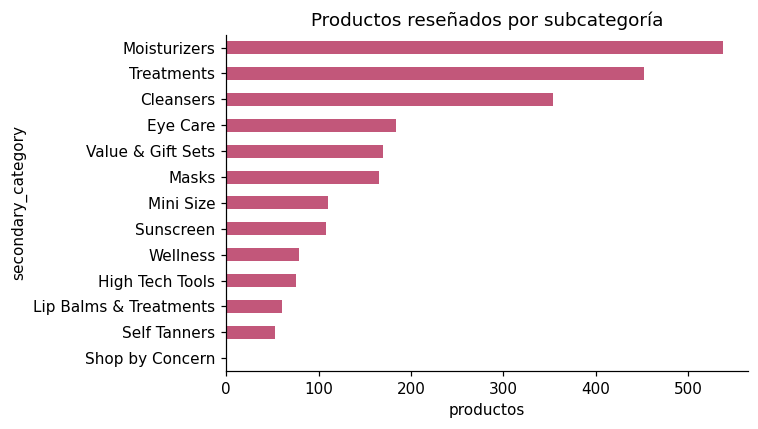

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
items.secondary_category.value_counts().sort_values().plot.barh(ax=ax, color=ROSA)
ax.set_title("Productos reseñados por subcategoría")
ax.set_xlabel("productos")
plt.tight_layout(); plt.savefig(FIG / "00_subcategorias.png"); plt.show()

## 2 · ¿Cuánta historia tiene cada persona?

Esta es la pregunta más importante. Un recomendador "aprende" de los patrones de las personas que reseñaron varios productos.

In [5]:
per_user = reviews.groupby("author_id").size()
summary = pd.Series({
    "personas": len(per_user),
    "1 reseña": (per_user == 1).mean(),
    "≥2": (per_user >= 2).mean(),
    "≥3": (per_user >= 3).mean(),
    "≥5": (per_user >= 5).mean(),
    "≥10": (per_user >= 10).mean(),
    "mediana": per_user.median(),
    "máximo": per_user.max(),
})
display(summary.to_frame("valor"))

# ¿Qué proporción de las reseñas viene de cada grupo?
for k in [3, 5, 10]:
    share = per_user[per_user >= k].sum() / per_user.sum()
    print(f"Personas con ≥{k} reseñas: {(per_user >= k).mean():.1%} de las personas, {share:.1%} de las reseñas")

,valor
personas,"503,216.000"
1 reseña,0.582
≥2,0.418
≥3,0.210
≥5,0.081
≥10,0.019
mediana,1.000
máximo,292.000


Personas con ≥3 reseñas: 21.0% de las personas, 54.1% de las reseñas
Personas con ≥5 reseñas: 8.1% de las personas, 34.3% de las reseñas
Personas con ≥10 reseñas: 1.9% de las personas, 16.4% de las reseñas


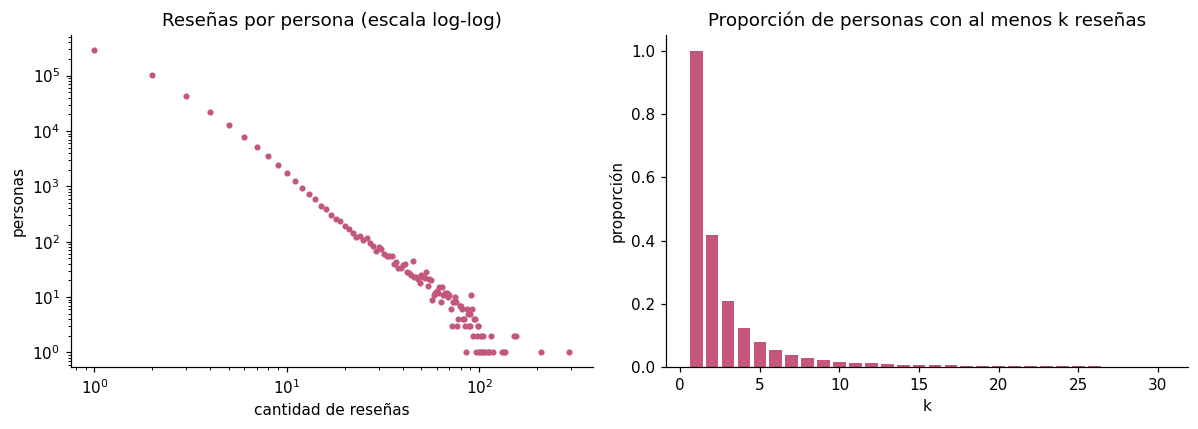

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

counts = per_user.value_counts().sort_index()
axes[0].loglog(counts.index, counts.values, "o", color=ROSA, ms=3)
axes[0].set(title="Reseñas por persona (escala log-log)", xlabel="cantidad de reseñas", ylabel="personas")

ccdf = (per_user.values[:, None] >= np.arange(1, 31)).mean(axis=0)
axes[1].bar(np.arange(1, 31), ccdf, color=ROSA)
axes[1].set(title="Proporción de personas con al menos k reseñas", xlabel="k", ylabel="proporción")
plt.tight_layout(); plt.savefig(FIG / "00_resenas_por_persona.png"); plt.show()

## 3 · ¿Qué tan concentradas están las reseñas en pocos productos?

Si pocos productos acumulan casi todas las reseñas, un baseline de popularidad va a ser muy fuerte. Esto también anticipa el **sesgo de popularidad**: el riesgo de que el modelo recomiende siempre los mismos productos.

El top 1% de los productos (23) acumula 13.1% de las reseñas
El top 5% de los productos (117) acumula 37.1% de las reseñas
El top 10% de los productos (235) acumula 53.5% de las reseñas
El top 20% de los productos (470) acumula 72.4% de las reseñas

Reseñas por producto: mediana 164, mínimo 1, máximo 16,115
Productos con <10 reseñas: 229 | <50: 691


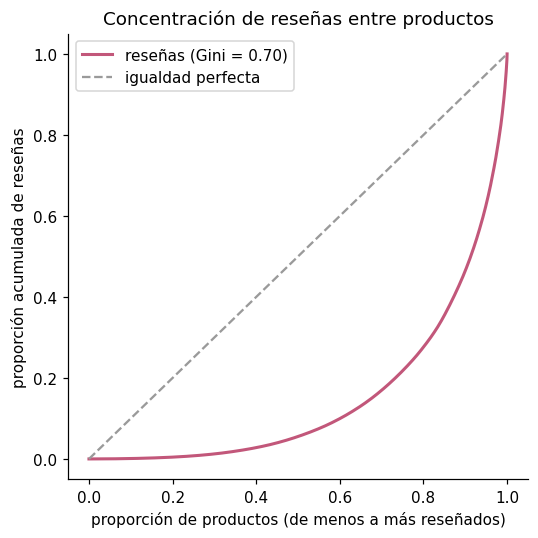

In [7]:
per_item = reviews.groupby("product_id").size().sort_values(ascending=False)
cum = per_item.cumsum() / per_item.sum()
for q in [0.01, 0.05, 0.10, 0.20]:
    n = max(1, int(len(per_item) * q))
    print(f"El top {q:.0%} de los productos ({n}) acumula {cum.iloc[n-1]:.1%} de las reseñas")
print(f"\nReseñas por producto: mediana {per_item.median():.0f}, mínimo {per_item.min()}, máximo {per_item.max():,}")
print(f"Productos con <10 reseñas: {(per_item < 10).sum()} | <50: {(per_item < 50).sum()}")

# Curva de Lorenz + Gini
x = np.linspace(0, 1, len(per_item) + 1)
lorenz = np.concatenate([[0], np.sort(per_item.values).cumsum() / per_item.sum()])
gini = 1 - 2 * np.trapz(lorenz, x)
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(x, lorenz, color=ROSA, lw=2, label=f"reseñas (Gini = {gini:.2f})")
ax.plot([0, 1], [0, 1], "--", color=GRIS, label="igualdad perfecta")
ax.set(title="Concentración de reseñas entre productos", xlabel="proporción de productos (de menos a más reseñados)", ylabel="proporción acumulada de reseñas")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "00_lorenz_productos.png"); plt.show()

## 4 · El perfil de piel: ¿qué tan completo está?

En cold start, el perfil es lo único que sabemos de la persona. Lo calculamos **por persona** (no por reseña), tomando el valor más frecuente de cada una.

In [8]:
profile_cols = ["skin_tone", "skin_type", "eye_color", "hair_color"]

def moda_por_persona(df, col):
    # Valor más frecuente de `col` para cada persona (vectorizado: contar, ordenar y quedarse con el primero)
    c = df.dropna(subset=[col]).groupby(["author_id", col], observed=True).size().rename("n").reset_index()
    c = c.sort_values(["author_id", "n"], ascending=[True, False]).drop_duplicates("author_id")
    return c.set_index("author_id")[col].astype(str)

users = reviews.groupby("author_id").size().rename("n_reseñas").to_frame()
for c in profile_cols:
    users[c] = moda_por_persona(reviews, c)
display(users[profile_cols].isna().mean().rename("% de personas sin el dato").to_frame())
print(f"Personas sin ningún dato de perfil: {users[profile_cols].isna().all(axis=1).mean():.1%}")
print(f"Personas con tono Y tipo de piel: {users[['skin_tone', 'skin_type']].notna().all(axis=1).mean():.1%}")

# ¿El perfil es consistente? Personas con más de un tono distinto en sus reseñas
multi = reviews.dropna(subset=["skin_tone"]).groupby("author_id", observed=True).skin_tone.nunique()
print(f"Personas con más de un tono de piel declarado: {(multi > 1).mean():.2%}")

,% de personas sin el dato
skin_tone,0.166
skin_type,0.113
eye_color,0.228
hair_color,0.233


Personas sin ningún dato de perfil: 10.6%
Personas con tono Y tipo de piel: 82.7%


Personas con más de un tono de piel declarado: 2.98%


## 5 · ¿Cuántos datos hay por tono de piel?

Es la base del análisis de fairness: si hay pocas personas de un tono, el recomendador tiene menos de qué aprender **y** nuestra medición del error es menos precisa.

,personas,reseñas,reseñas_media,con_3_o_mas,% personas
skin_tone,,,,,
porcelain,694,879,1.267,42,0.002
fair,94824,219238,2.312,22558,0.226
fairLight,24883,61802,2.484,6609,0.059
light,116890,279551,2.392,28628,0.279
lightMedium,90743,214184,2.360,21989,0.216
medium,31796,71114,2.237,7017,0.076
mediumTan,30031,67774,2.257,6906,0.072
olive,847,1034,1.221,41,0.002
tan,15907,34025,2.139,3343,0.038


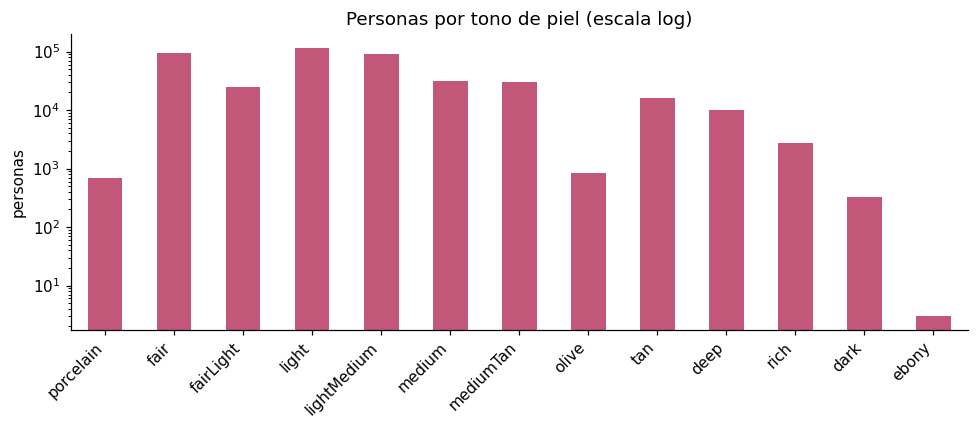

In [9]:
tone = users.dropna(subset=["skin_tone"]).copy()
tone["skin_tone"] = pd.Categorical(tone.skin_tone, categories=SKIN_TONE_ORDER + ["notSureST"], ordered=True)
by_tone = tone.groupby("skin_tone", observed=True).agg(
    personas=("n_reseñas", "size"),
    reseñas=("n_reseñas", "sum"),
    reseñas_media=("n_reseñas", "mean"),
    con_3_o_mas=("n_reseñas", lambda s: (s >= 3).sum()),
)
by_tone["% personas"] = by_tone.personas / by_tone.personas.sum()
display(by_tone)

fig, ax = plt.subplots(figsize=(9, 4))
by_tone.personas.drop("notSureST", errors="ignore").plot.bar(ax=ax, color=ROSA, logy=True)
ax.set(title="Personas por tono de piel (escala log)", xlabel="", ylabel="personas")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.savefig(FIG / "00_personas_por_tono.png"); plt.show()

In [10]:
display(pd.crosstab(tone.skin_tone, tone.skin_type, normalize="index").round(2))

skin_type,combination,dry,normal,oily
skin_tone,,,,
porcelain,0.530,0.270,0.110,0.090
fair,0.550,0.210,0.140,0.100
fairLight,0.520,0.260,0.120,0.100
light,0.560,0.190,0.150,0.110
lightMedium,0.570,0.160,0.140,0.130
medium,0.560,0.160,0.130,0.150
mediumTan,0.570,0.140,0.130,0.160
olive,0.610,0.120,0.130,0.140
tan,0.550,0.150,0.110,0.190


## 6 · ¿Qué significa "le gustó"?

Opciones: `rating ≥ 4`, `rating == 5` o `is_recommended == 1`. Vemos cuánto coinciden y si cambian por tono de piel (si un grupo puntúa sistemáticamente distinto, la definición importa para el análisis de fairness).

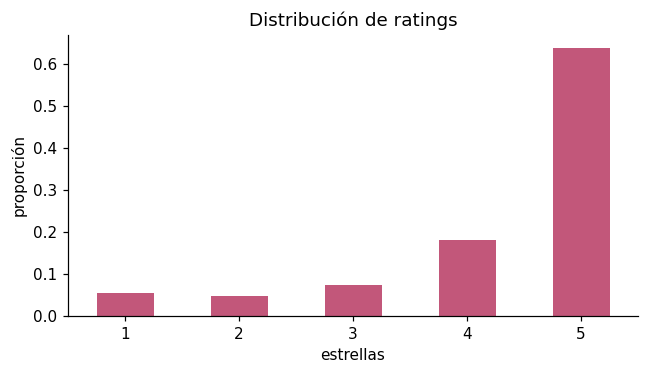

is_recommended faltante: 15.3%


is_recommended,0.000,1.000
rating,,
1,0.992,0.008
2,0.963,0.037
3,0.643,0.357
4,0.034,0.966
5,0.001,0.999


In [11]:
fig, ax = plt.subplots(figsize=(6, 3.5))
reviews.rating.value_counts(normalize=True).sort_index().plot.bar(ax=ax, color=ROSA)
ax.set(title="Distribución de ratings", xlabel="estrellas", ylabel="proporción")
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig(FIG / "00_ratings.png"); plt.show()

print(f"is_recommended faltante: {reviews.is_recommended.isna().mean():.1%}")
display(pd.crosstab(reviews.rating, reviews.is_recommended, normalize="index").round(3))

In [12]:
r = reviews.dropna(subset=["skin_tone"]).copy()
r["skin_tone"] = pd.Categorical(r.skin_tone, categories=SKIN_TONE_ORDER + ["notSureST"], ordered=True)
display(r.groupby("skin_tone", observed=True).agg(
    reseñas=("rating", "size"),
    rating_medio=("rating", "mean"),
    pct_4_o_mas=("rating", lambda s: (s >= 4).mean()),
    pct_5=("rating", lambda s: (s == 5).mean()),
    pct_recomienda=("is_recommended", "mean"),
))

,reseñas,rating_medio,pct_4_o_mas,pct_5,pct_recomienda
skin_tone,,,,,
porcelain,1609,4.229,0.792,0.649,0.810
fair,207954,4.274,0.812,0.626,0.832
fairLight,56211,4.255,0.803,0.624,0.827
light,266306,4.301,0.821,0.635,0.840
lightMedium,196483,4.319,0.827,0.646,0.845
medium,70463,4.331,0.833,0.654,0.856
mediumTan,62428,4.282,0.816,0.635,0.834
olive,1726,4.260,0.811,0.645,0.822
tan,33665,4.284,0.821,0.622,0.846


## 7 · El tiempo

El split leave-last-out usa la última reseña de cada persona. Revisamos el rango de fechas, si hay huecos y si hay reseñas repetidas de la misma persona al mismo producto.

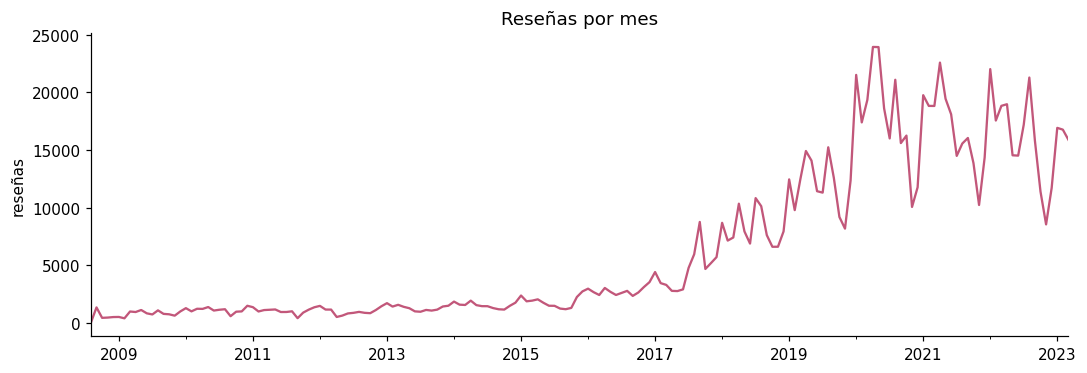

Pares persona-producto con más de una reseña: 4,586 (0.42%)


Personas con ≥2 reseñas, todas el mismo día: 34.7%


In [13]:
monthly = reviews.set_index("submission_time").resample("ME").size()
fig, ax = plt.subplots(figsize=(10, 3.5))
monthly.plot(ax=ax, color=ROSA)
ax.set(title="Reseñas por mes", xlabel="", ylabel="reseñas")
plt.tight_layout(); plt.savefig(FIG / "00_resenas_por_mes.png"); plt.show()

dup = reviews.groupby(["author_id", "product_id"]).size()
print(f"Pares persona-producto con más de una reseña: {(dup > 1).sum():,} ({(dup > 1).mean():.2%})")

same_day = reviews.groupby("author_id").submission_time.agg(["min", "max", "size"])
same_day = same_day[same_day["size"] >= 2]
print(f"Personas con ≥2 reseñas, todas el mismo día: {(same_day['min'] == same_day['max']).mean():.1%}")

## 8 · Simulación de los splits

¿Cuántos datos quedan para entrenar y evaluar con las reglas que planeamos?

- **Positivo** = `rating ≥ 4` (provisorio, ver sección 6).
- **Set con historial**: personas con ≥ `K` positivos. Su último positivo va a test, el resto a train.
- **Set cold start**: personas que el modelo nunca ve, solo con su perfil.

In [14]:
pos = reviews[reviews.rating >= 4]
pos_per_user = pos.groupby("author_id").size()
rows = []
for K in [2, 3, 5]:
    u = pos_per_user[pos_per_user >= K].index
    rows.append({"K": K, "personas": len(u), "positivos train": int(pos_per_user[u].sum() - len(u)), "casos de test": len(u)})
display(pd.DataFrame(rows).set_index("K"))

# Casos de test por tono con K=3: ¿alcanzan para medir el recall de cada grupo?
K = 3
u3 = users.loc[pos_per_user[pos_per_user >= K].index.intersection(users.index)]
t = u3.skin_tone.value_counts().reindex(SKIN_TONE_ORDER).dropna().astype(int).rename("casos de test (K=3)").to_frame()
# Error estándar aproximado de un recall de ~0.2 con esa cantidad de casos
t["± error estándar (recall≈0.2)"] = np.sqrt(0.2 * 0.8 / t.iloc[:, 0])
display(t)

,personas,positivos train,casos de test
K,,,
2,173659,467725,173659
3,83341,377407,83341
5,30403,253620,30403


,casos de test (K=3),± error estándar (recall≈0.2)
skin_tone,,
porcelain,29,0.074
fair,17675,0.003
fairLight,5175,0.006
light,22665,0.003
lightMedium,17604,0.003
medium,5609,0.005
mediumTan,5450,0.005
olive,33,0.070
tan,2674,0.008


## 9 · Conclusiones y decisiones

### Lo que encontramos

**El proyecto es viable, pero el cold start manda.**
- 58% de las personas tiene una sola reseña; solo 21% tiene ≥3. Ese 21%, sin embargo, aporta **54% de las reseñas**: hay suficiente señal para aprender del historial.
- Con `K = 3` positivos por persona quedan **83 mil personas** para el set con historial (377 mil positivos de train y 83 mil casos de test).

**El catálogo está completo y la popularidad va a ser un rival fuerte.**
- Las reseñas cubren 2.351 productos, todos de Skincare, y todos están en `product_info`. Faltan ingredientes solo en el 5,4%: la torre del producto tiene sus features.
- El top 10% de los productos acumula 53,5% de las reseñas. El baseline de popularidad va a ser difícil de vencer, y hay que medir el sesgo de popularidad del modelo.

**El perfil de piel es usable.**
- 82,7% de las personas declara tono y tipo de piel. Solo 3% declara más de un tono, así que usar el valor más frecuente es razonable.
- El tipo de piel cambia con el tono: la piel grasa pasa de ~10% en tonos claros a ~22–25% en deep/rich. Tono y tipo no son independientes, y el modelo va a poder aprovechar eso.

**El desbalance por tono es fuerte, pero el análisis de fairness es posible si agrupamos.**
- fair + light + lightMedium = 72% de las personas. deep + rich + dark + ebony = 3%.
- porcelain, olive, dark y ebony tienen muy pocos casos de test (≤33), con un error estándar de ±7–8 puntos en el recall: no se pueden medir por separado.
- Llama la atención que porcelain, olive y dark tengan en promedio ~1,2–1,5 reseñas por persona, contra ~2,2–2,5 del resto. Hipótesis a verificar: son opciones que se agregaron más tarde al formulario.

**"Le gustó" no depende del tono.**
- `rating ≥ 4` y `is_recommended` coinciden casi siempre (96–100% en 4 y 5 estrellas). El rating 3 es ambiguo: 36% lo recomienda.
- El porcentaje de reseñas con 4+ es parecido en todos los tonos (79–83%). Si el modelo recomienda peor a un grupo, no va a ser porque ese grupo puntúa distinto. Eso hace más limpio el análisis de fairness.

**Un problema para el split temporal.**
- 35% de las personas con ≥2 reseñas las escribió **todas el mismo día**, así que "la última" no está bien definida.
- Las reseñas van de 2008 a 2023, pero la gran mayoría es de 2019 en adelante.

### Decisiones para el paso 1

1. **Positivo = `rating ≥ 4`.** No tiene faltantes (`is_recommended` falta en 15%) y casi coincide con "lo recomienda".
2. **Set con historial: personas con ≥3 positivos.**
3. **Desempate del leave-last-out:** si hay varias reseñas en la última fecha, se elige una al azar con semilla fija, y las demás de ese mismo día **no** van a train (para no filtrar información de la misma "sesión").
4. **Grupos de tono para fairness:**
   - *claro*: porcelain, fair, fairLight
   - *light*
   - *medio*: lightMedium, medium, mediumTan, olive
   - *tan*
   - *oscuro*: deep, rich, dark, ebony (~2.100 casos de test, ±0,9 puntos)
5. Las personas sin tono declarado entran al entrenamiento con la categoría "desconocido", pero quedan afuera del análisis por tono.
6. **Productos con <10 reseñas** (229) se mantienen en el catálogo; la torre del producto puede representarlos por sus features aunque tengan pocos datos.